# Previsão de viralidade em YouTube Shorts

**Projeto Final · Machine Learning Clássico · Prof. Dr. Rodrigo Ramos Silva · 2026**

**Pergunta:** com as informações que existem *antes* de publicar (duração, categoria, idioma e descrição), um modelo
clássico consegue dizer se um Short vai ficar entre os 20% mais vistos?

**Teste no mundo real:** depois de treinar no dataset público, aplicamos os modelos aos Shorts do canal
*Simulando o Mundo*, produzidos por uma pipeline automática, e conferimos se o modelo ordena os vídeos como as views reais.

| Item | Escolha |
|---|---|
| Tipo de problema | Classificação binária |
| Alvo | `viral` = 1 se as views estão no top 20% do dataset |
| Dataset | ShortVideo (Zenodo 15446544), parte YouTube: 10.925 Shorts |
| Modelos | Regressão Logística, KNN, Árvore de Decisão e Random Forest (ensemble) |
| Otimização | `GridSearchCV` com validação cruzada estratificada de 5 dobras, só no treino |
| Métricas | Accuracy, Precision, Recall, F1 e ROC AUC no teste; matriz de confusão e curva ROC |

Para rodar: `python -m src.baixar_dados` (dataset) e, para a parte do canal, `python -m src.canal`.

In [1]:
import re                                             # expressões regulares para ler duração e texto
from pathlib import Path                              # caminhos de arquivo independentes do sistema

import numpy as np                                    # contas numéricas
import pandas as pd                                   # tabelas
import matplotlib.pyplot as plt                       # gráficos
from scipy.stats import spearmanr                     # correlação de postos (ordem)

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             ConfusionMatrixDisplay, roc_curve)
from sklearn.inspection import permutation_importance

RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent   # funciona rodando da raiz ou de notebooks/
ARQ_YOUTUBE = RAIZ / "data" / "raw" / "youtube_metadata_dehydrated.jsonl"  # dataset público
ARQ_CANAL = RAIZ / "data" / "canal" / "simulando_o_mundo.csv"             # vídeos do canal (python -m src.canal)
FIGURAS = RAIZ / "reports" / "figuras" / "youtube"                         # onde os gráficos são salvos
FIGURAS.mkdir(parents=True, exist_ok=True)
SEMENTE = 42                                          # mesma semente em tudo: resultados reproduzíveis
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Dados e EDA

A EDA aqui serve para tomar decisões: quais colunas entram, o que precisa de tratamento e como medir o alvo.

In [2]:
if not ARQ_YOUTUBE.exists():                           # baixa do Zenodo se ainda não estiver na máquina
    import sys; sys.path.insert(0, str(RAIZ))
    from src.baixar_dados import baixar
    baixar()

bruto = pd.read_json(ARQ_YOUTUBE, lines=True)          # uma linha por Short
print("Linhas x colunas:", bruto.shape)
bruto.drop(columns=[f"keyframe{i}" for i in range(1, 6)]).head(3)

Linhas x colunas: (10925, 16)


,folder_id,description,category_id,defaultLanguage,duration,caption,view_count,like_count,dislike_count,comment_count,day
0,23576b790fd24397,,22,en,PT1M,false,2665827,75064,0,265,28-12-2024
1,362cc17be4e64546,✅ REDES SOCIAIS +8k\n🔗Instagram: https://www.i...,28,pt-BR,PT27S,false,19658,2001,0,36,03-01-2025
2,93c005b387ec486a,,20,pt-BR,PT12S,false,575,35,0,8,01-01-2025


In [3]:
visao = pd.DataFrame({
    "tipo": bruto.dtypes.astype(str),
    "nulos": bruto.isna().sum(),
    "texto_vazio": [(bruto[c].astype(str).str.strip() == "").sum() if bruto[c].dtype == object else 0 for c in bruto],
})
visao

,tipo,nulos,texto_vazio
folder_id,str,0,0
description,str,0,0
category_id,int64,0,0
defaultLanguage,str,0,0
duration,str,0,0
caption,str,0,0
view_count,int64,0,0
like_count,int64,0,0
dislike_count,int64,0,0
comment_count,int64,0,0


**Leitura das colunas e decisões**

| Coluna | O que é | Decisão |
|---|---|---|
| `view_count` | views no dia da coleta | vira o **alvo** |
| `like_count`, `comment_count`, `dislike_count` | engajamento depois da publicação | **fora**: só existe depois que o vídeo já foi visto (vazamento) |
| `duration` | duração em ISO 8601 (`PT1M5S`) | converter para segundos |
| `category_id` | categoria do YouTube | one-hot; categorias raras agrupadas |
| `defaultLanguage` | idioma declarado (78% vazio) | agrupar em pt, en, outro e não informado |
| `description` | descrição (66% vazia) | extrair contagens: tamanho, hashtags, links, emojis |
| `caption` | legenda enviada | **fora**: só 56 de 10.925 têm legenda (quase constante) |
| `keyframe1..5` | rótulos do Google SafeSearch | **fora**: não temos isso para os vídeos do canal |
| `day` | **data da coleta**, não da publicação | **fora**; não dá para saber a idade do vídeo (limitação) |

In [4]:
def iso_para_segundos(texto):
    # PT1M5S -> 65; P0D -> 0. Lê só a parte depois do T (horas, minutos, segundos).
    partes = {u: int(n) for n, u in re.findall(r"(\d+)([HMS])", str(texto).split("T")[-1])}
    return partes.get("H", 0) * 3600 + partes.get("M", 0) * 60 + partes.get("S", 0)

dados = bruto.copy()                                   # preserva o bruto
dados["duracao_s"] = dados["duration"].map(iso_para_segundos)
fora = (dados["duracao_s"] <= 0) | (dados["duracao_s"] > 180)   # Shorts têm até 3 min; 0 s é erro de cadastro
print(f"Removidos por duração inválida: {fora.sum()} ({fora.mean():.1%})")
dados = dados.loc[~fora].reset_index(drop=True)

LIMIAR = dados["view_count"].quantile(0.80)            # definição do problema: top 20% de views
dados["viral"] = (dados["view_count"] >= LIMIAR).astype(int)
print(f"Limiar de viral: {LIMIAR:,.0f} views".replace(",", "."))
print("Proporção de cada classe:")
print(dados["viral"].value_counts(normalize=True).round(3))

Removidos por duração inválida: 145 (1.3%)
Limiar de viral: 13.862.339 views
Proporção de cada classe:
viral
0    0.8
1    0.2
Name: proportion, dtype: float64


**Amostra dos dados**

Dez Shorts sorteados do dataset já limpo: cada linha é um vídeo, com as entradas que existem antes de publicar (descrição, duração, categoria e idioma), as views e o alvo `viral`.

In [ ]:
amostra = dados.sample(10, random_state=SEMENTE)          # sorteio fixo: a tabela é sempre a mesma
amostra = pd.DataFrame({
    "descrição": amostra["description"].fillna("").str.replace("\n", " ").str.slice(0, 60),  # corta textos longos
    "duração (s)": amostra["duracao_s"],
    "categoria": amostra["category_id"],
    "idioma": amostra["defaultLanguage"].fillna("não informado"),
    "views": amostra["view_count"],
    "viral": amostra["viral"],
})
amostra

,descrição,duração (s),categoria,idioma,views,viral
9752,,11,22,,30202770,1
7465,Leopard suddenly attacks wild animals at close...,10,26,en,66881977,1
8622,,25,10,pt-BR,148643,0
1775,,12,22,,2993,0
3465,,6,20,,15107,0
408,,41,15,,700375,0
4028,,8,23,pt,15832,0
3470,Video auf TikTok: https://www.tiktok.com/@noel...,10,24,,571322844,1
2055,,61,20,,2247493,0
8933,,16,22,,1672,0


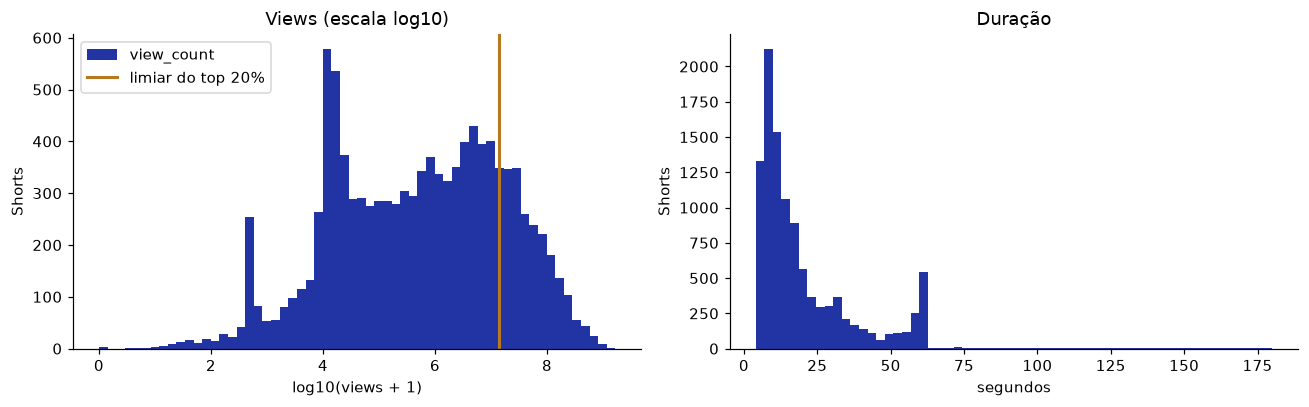

         view_count  duracao_s
count  1.078000e+04    10780.0
mean   1.966943e+07       20.9
std    6.784925e+07       19.0
min    0.000000e+00        4.0
25%    2.537020e+04        8.0
50%    6.556040e+05       14.0
75%    8.496684e+06       27.0
80%    1.386234e+07       31.0
90%    4.413235e+07       53.0
max    1.669423e+09      180.0


In [5]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.8))
np.log10(dados["view_count"] + 1).plot.hist(bins=60, ax=eixos[0], color="#2234A4")
eixos[0].axvline(np.log10(LIMIAR), color="#B7791F", lw=2, label="limiar do top 20%")
eixos[0].set(title="Views (escala log10)", xlabel="log10(views + 1)", ylabel="Shorts"); eixos[0].legend()
dados["duracao_s"].plot.hist(bins=60, ax=eixos[1], color="#2234A4")
eixos[1].set(title="Duração", xlabel="segundos", ylabel="Shorts")
plt.tight_layout(); plt.savefig(FIGURAS / "eda_views_duracao.png", bbox_inches="tight"); plt.show()

print(dados[["view_count", "duracao_s"]].describe(percentiles=[.25, .5, .75, .8, .9]).round(1))

**O que a EDA mostra:** as views são extremamente concentradas (mediana na casa das centenas de milhares,
top 20% acima de 13,9 milhões), por isso o alvo é binário e a classe positiva tem 20%: um **desbalanceamento
moderado**, tratado com `class_weight="balanced"` e com métricas que não dependem só de acurácia.
As durações também são assimétricas (a maioria tem menos de 30 s), por isso as contagens passam por `log1p`.

## 2. Feature engineering

Uma única função cria as variáveis, para o dataset e para os vídeos do canal. Assim o modelo vê exatamente
as mesmas colunas nos dois casos.

In [6]:
EMOJI = re.compile("[\U0001F300-\U0001FAFF☀-➿]")   # faixas Unicode mais comuns de emoji

def criar_features(tabela):
    texto = tabela["description"].fillna("")
    idioma = tabela["defaultLanguage"].fillna("").str.lower().str[:2]
    grupo_idioma = np.select([idioma == "pt", idioma == "en", idioma == ""], ["pt", "en", "nao_informado"], "outro")
    return pd.DataFrame({
        "duracao_s": tabela["duracao_s"].astype(float),
        "tem_descricao": (texto.str.strip() != "").astype(int),
        "caracteres_descricao": texto.str.len(),
        "hashtags": texto.str.count(r"#\w+"),
        "links": texto.str.count(r"https?://"),
        "emojis": texto.map(lambda t: len(EMOJI.findall(t))),
        "categoria": tabela["category_id"].astype(int).astype(str),
        "idioma": grupo_idioma,
    }, index=tabela.index)

X = criar_features(dados)
y = dados["viral"]
NUMERICAS = ["duracao_s", "tem_descricao", "caracteres_descricao", "hashtags", "links", "emojis"]
CATEGORICAS = ["categoria", "idioma"]
X.describe(include="all").T[["count", "unique", "top", "mean", "50%", "max"]]

,count,unique,top,mean,50%,max
duracao_s,10780.0,NaN,NaN,20.859926,14.0,180.0
tem_descricao,10780.0,NaN,NaN,0.327737,0.0,1.0
caracteres_descricao,10780.0,NaN,NaN,178.023933,0.0,5000.0
hashtags,10780.0,NaN,NaN,4.309091,0.0,524.0
links,10780.0,NaN,NaN,0.345455,0.0,57.0
emojis,10780.0,NaN,NaN,0.587848,0.0,152.0
categoria,10780,15,22,NaN,NaN,NaN
idioma,10780,4,nao_informado,NaN,NaN,NaN


## 3. Divisão dos dados e pré-processamento

- **Divisão:** 80% treino e 20% teste, estratificada pelo alvo. O teste fica guardado até o fim.
- **Pré-processamento dentro de um `Pipeline`:** imputação pela mediana, `log1p` nas contagens e `StandardScaler`
  nas numéricas; `OneHotEncoder` nas categóricas, juntando categorias com menos de 100 vídeos em "infrequente".
  Tudo é ajustado só no treino de cada dobra, então não há vazamento do teste.
- O `StandardScaler` importa para a Regressão Logística e o KNN (que usa distâncias). Para árvores ele é inofensivo.

In [7]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMENTE)
print("Treino:", X_treino.shape, "| Teste:", X_teste.shape)
print("Viral no treino:", round(y_treino.mean(), 3), "| no teste:", round(y_teste.mean(), 3))

preprocessamento = ColumnTransformer([
    ("num", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),     # nenhuma numérica tem nulo hoje, mas o pipeline fica seguro
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),         # reduz a assimetria das contagens
        ("padronizar", StandardScaler()),                  # média 0 e desvio 1, aprendidos no treino
    ]), NUMERICAS),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100, sparse_output=False), CATEGORICAS),
])

Treino: (8624, 8) | Teste: (2156, 8)
Viral no treino: 0.2 | no teste: 0.2


## 4. Modelos e otimização com GridSearchCV

| Modelo | Por que entra | Hiperparâmetros buscados |
|---|---|---|
| Regressão Logística | linha de base linear e interpretável | `C` (força da regularização) |
| KNN | classifica pelos vizinhos mais parecidos | `n_neighbors`, `weights` |
| Árvore de Decisão | regras fáceis de ler | `max_depth`, `min_samples_leaf` |
| Random Forest | **ensemble** de árvores (bagging + sorteio de atributos), reduz a variância de uma árvore só | `max_depth`, `min_samples_leaf` |

A busca usa ROC AUC como critério, porque ele mede a capacidade de **ordenar** os vídeos sem depender de um limiar.

In [8]:
modelos = {
    "Regressão Logística": (LogisticRegression(max_iter=2000, class_weight="balanced"),
                            {"modelo__C": [0.01, 0.1, 1, 10]}),
    "KNN": (KNeighborsClassifier(),
            {"modelo__n_neighbors": [15, 51, 101, 201], "modelo__weights": ["uniform", "distance"]}),
    "Árvore de Decisão": (DecisionTreeClassifier(class_weight="balanced", random_state=SEMENTE),
                          {"modelo__max_depth": [3, 5, 8, 12], "modelo__min_samples_leaf": [20, 50, 100]}),
    "Random Forest": (RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEMENTE, n_jobs=-1),
                      {"modelo__max_depth": [6, 10, None], "modelo__min_samples_leaf": [5, 20]}),
}

validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
buscas = {}
for nome, (estimador, grade) in modelos.items():
    pipe = Pipeline([("prep", preprocessamento), ("modelo", estimador)])
    busca = GridSearchCV(pipe, grade, scoring="roc_auc", cv=validacao, n_jobs=-1)
    busca.fit(X_treino, y_treino)                       # a busca só enxerga o treino
    buscas[nome] = busca
    melhores = {k.replace("modelo__", ""): v for k, v in busca.best_params_.items()}
    print(f"{nome:20s} AUC na validação cruzada = {busca.best_score_:.3f}   {melhores}")

MELHOR = max(buscas, key=lambda n: buscas[n].best_score_)   # escolha pela validação cruzada, não pelo teste
print("\nModelo escolhido pela validação cruzada:", MELHOR)

Regressão Logística  AUC na validação cruzada = 0.757   {'C': 1}


KNN                  AUC na validação cruzada = 0.743   {'n_neighbors': 51, 'weights': 'uniform'}


Árvore de Decisão    AUC na validação cruzada = 0.757   {'max_depth': 5, 'min_samples_leaf': 100}


Random Forest        AUC na validação cruzada = 0.772   {'max_depth': 10, 'min_samples_leaf': 5}

Modelo escolhido pela validação cruzada: Random Forest


## 5. Comparação no conjunto de teste

Limiar de decisão de 0,5. A linha "Base" é um classificador que sempre responde "não viral": qualquer modelo útil
precisa superá-lo em Recall, F1 e AUC (a acurácia dele já é 80% sem aprender nada).

In [9]:
probas = {}
linhas = []
for nome, busca in buscas.items():
    p = busca.predict_proba(X_teste)[:, 1]              # probabilidade de ser viral
    probas[nome] = p
    pred = (p >= 0.5).astype(int)
    linhas.append({"Modelo": nome,
                   "Accuracy": accuracy_score(y_teste, pred),
                   "Precision": precision_score(y_teste, pred, zero_division=0),
                   "Recall": recall_score(y_teste, pred),
                   "F1": f1_score(y_teste, pred),
                   "ROC AUC": roc_auc_score(y_teste, p)})

base = DummyClassifier(strategy="most_frequent").fit(X_treino, y_treino)
pred_base = base.predict(X_teste)
linhas.append({"Modelo": "Base: sempre 'não viral'", "Accuracy": accuracy_score(y_teste, pred_base),
               "Precision": 0.0, "Recall": 0.0, "F1": 0.0, "ROC AUC": 0.5})

resultados = pd.DataFrame(linhas).set_index("Modelo").round(3)
(RAIZ / "reports" / "tabelas").mkdir(parents=True, exist_ok=True)
resultados.to_csv(RAIZ / "reports" / "tabelas" / "youtube_comparacao_teste.csv")
resultados

,Accuracy,Precision,Recall,F1,ROC AUC
Modelo,,,,,
Regressão Logística,0.714,0.385,0.722,0.502,0.779
KNN,0.806,0.638,0.070,0.126,0.766
Árvore de Decisão,0.670,0.353,0.784,0.487,0.767
Random Forest,0.697,0.375,0.780,0.507,0.791
Base: sempre 'não viral',0.800,0.000,0.000,0.000,0.500


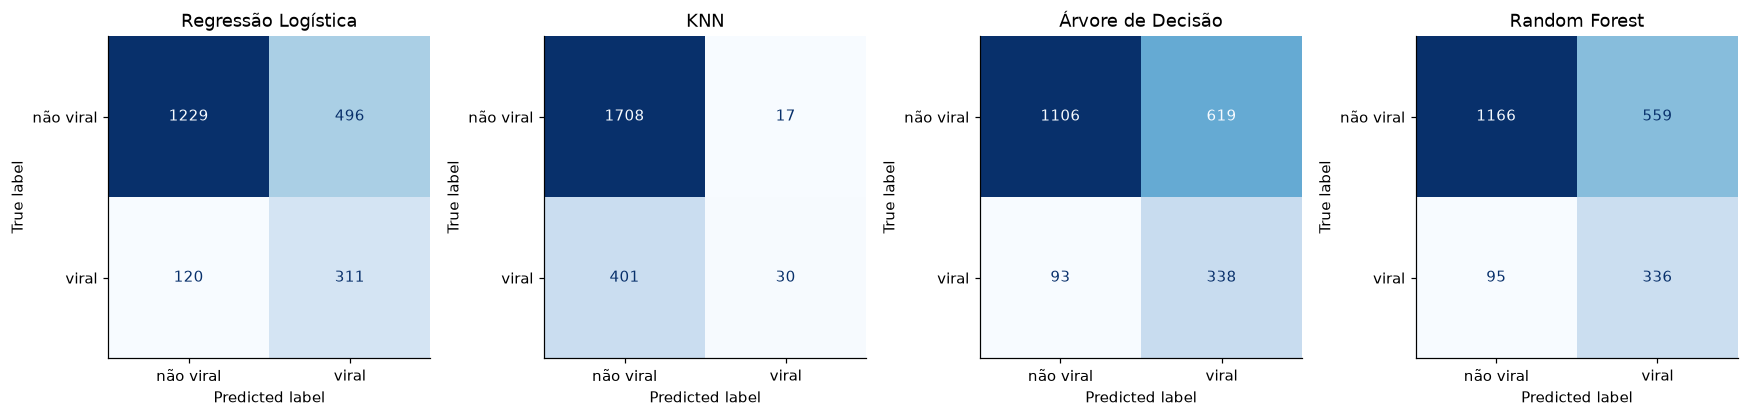

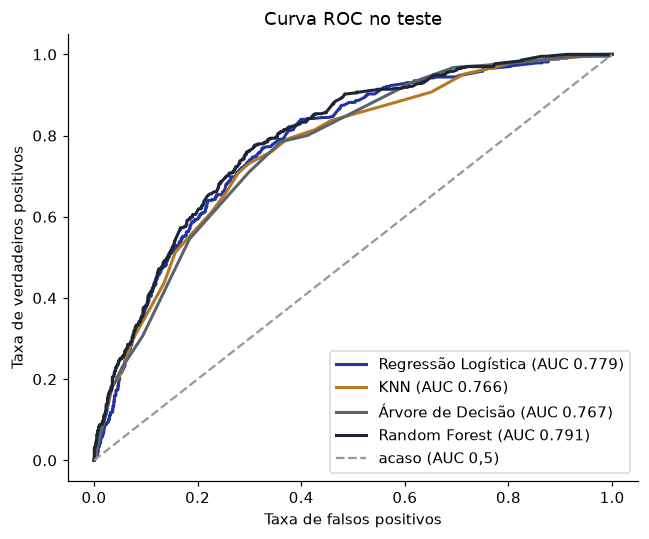

In [10]:
fig, eixos = plt.subplots(1, 4, figsize=(16, 3.8))
for eixo, nome in zip(eixos, buscas):
    ConfusionMatrixDisplay.from_predictions(y_teste, (probas[nome] >= 0.5).astype(int), ax=eixo, colorbar=False,
                                            display_labels=["não viral", "viral"], cmap="Blues")
    eixo.set_title(nome)
plt.tight_layout(); plt.savefig(FIGURAS / "matrizes_confusao.png", bbox_inches="tight"); plt.show()

fig, eixo = plt.subplots(figsize=(6, 5))
cores = ["#2234A4", "#B7791F", "#5A6272", "#1D2433"]
for cor, nome in zip(cores, buscas):
    fpr, tpr, _ = roc_curve(y_teste, probas[nome])
    eixo.plot(fpr, tpr, color=cor, lw=2, label=f"{nome} (AUC {roc_auc_score(y_teste, probas[nome]):.3f})")
eixo.plot([0, 1], [0, 1], ls="--", color="#999", label="acaso (AUC 0,5)")
eixo.set(title="Curva ROC no teste", xlabel="Taxa de falsos positivos", ylabel="Taxa de verdadeiros positivos")
eixo.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIGURAS / "curvas_roc.png", bbox_inches="tight"); plt.show()

## 6. Interpretabilidade

**Importância por permutação** (no teste): embaralha uma variável por vez e mede quanto o AUC cai.
Vale para qualquer modelo e é medida nas variáveis originais, antes do one-hot.

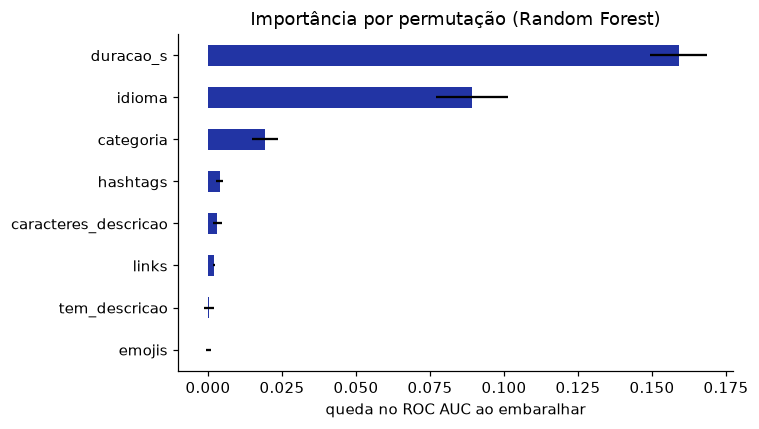

duracao_s               0.1590
idioma                  0.0892
categoria               0.0193
hashtags                0.0039
caracteres_descricao    0.0032
links                   0.0020
tem_descricao           0.0003
emojis                  0.0001
dtype: float64

In [11]:
modelo_final = buscas[MELHOR].best_estimator_
imp = permutation_importance(modelo_final, X_teste, y_teste, scoring="roc_auc", n_repeats=10, random_state=SEMENTE, n_jobs=-1)
importancia = pd.Series(imp.importances_mean, index=X_teste.columns).sort_values()

fig, eixo = plt.subplots(figsize=(7, 4))
importancia.plot.barh(ax=eixo, color="#2234A4", xerr=imp.importances_std[importancia.index.map(list(X_teste.columns).index)])
eixo.set(title=f"Importância por permutação ({MELHOR})", xlabel="queda no ROC AUC ao embaralhar")
plt.tight_layout(); plt.savefig(FIGURAS / "importancia_permutacao.png", bbox_inches="tight"); plt.show()
importancia.sort_values(ascending=False).round(4)

In [12]:
# Coeficientes da Regressão Logística: sinal = direção do efeito (já com as variáveis padronizadas)
logistica = buscas["Regressão Logística"].best_estimator_
nomes = logistica.named_steps["prep"].get_feature_names_out()
coef = pd.Series(logistica.named_steps["modelo"].coef_[0], index=nomes).sort_values()
coef.round(3)

cat__idioma_pt                      -1.930
cat__categoria_infrequent_sklearn   -0.663
cat__categoria_27                   -0.643
num__caracteres_descricao           -0.360
cat__categoria_22                   -0.228
cat__categoria_1                    -0.117
cat__categoria_2                    -0.117
cat__categoria_20                   -0.092
cat__idioma_nao_informado            0.008
cat__categoria_10                    0.044
num__emojis                          0.047
num__links                           0.072
num__hashtags                        0.084
cat__categoria_19                    0.085
cat__categoria_28                    0.104
cat__categoria_24                    0.147
cat__categoria_23                    0.150
cat__categoria_17                    0.183
num__tem_descricao                   0.428
cat__categoria_26                    0.483
cat__categoria_15                    0.580
num__duracao_s                       0.692
cat__idioma_en                       0.840
cat__idioma

## 7. Teste no mundo real: os Shorts do canal *Simulando o Mundo*

O canal foi criado em 05/11/2026 e publica Shorts “E se…?” feitos por uma pipeline automática.
Nenhum vídeo dele chega perto do limiar de viral do dataset, então a pergunta aqui não é “acertou a classe?”,
e sim: **o modelo ordena os vídeos do canal na mesma ordem das views reais?** Medimos isso com a correlação de
Spearman entre a probabilidade prevista e as views.

Como os vídeos têm idades diferentes, usamos duas medidas: views totais (todos os vídeos) e views até o 2º dia
do Analytics (janela igual; só os vídeos que já têm esses dois dias).

In [ ]:
if not ARQ_CANAL.exists():
    raise SystemExit("Rode antes: python -m src.canal")

canal = pd.read_csv(ARQ_CANAL)
X_canal = criar_features(canal)
for nome, busca in buscas.items():
    canal[nome] = busca.predict_proba(X_canal)[:, 1]

# onde os vídeos do canal caem em relação ao dataset
print(f"Shorts do dataset com duração >= {canal['duracao_s'].min():.0f} s: {(dados['duracao_s'] >= canal['duracao_s'].min()).mean():.1%}")
print(f"Shorts do dataset na categoria 28 (Ciência e Tecnologia): {(dados['category_id'] == 28).mean():.1%}")
print(f"Probabilidade de viral ({MELHOR}) no canal: de {canal[MELHOR].min():.3f} a {canal[MELHOR].max():.3f}; "
      f"no teste do dataset, mediana {np.median(probas[MELHOR]):.3f}")

colunas = ["producao", "duracao_s", "views", "views_ate_dia2", MELHOR]
canal[colunas].sort_values("views", ascending=False).round(3)

In [ ]:
def spearman(a, b):
    ok = a.notna() & b.notna()
    rho, p = spearmanr(a[ok], b[ok])
    return pd.Series({"n": int(ok.sum()), "rho": round(rho, 3), "p-valor": round(p, 3)})

ordem = pd.DataFrame({
    (nome, alvo): spearman(canal[nome], canal[alvo])
    for nome in buscas for alvo in ["views", "views_ate_dia2"]
}).T
ordem.index.names = ["modelo", "comparado com"]
ordem

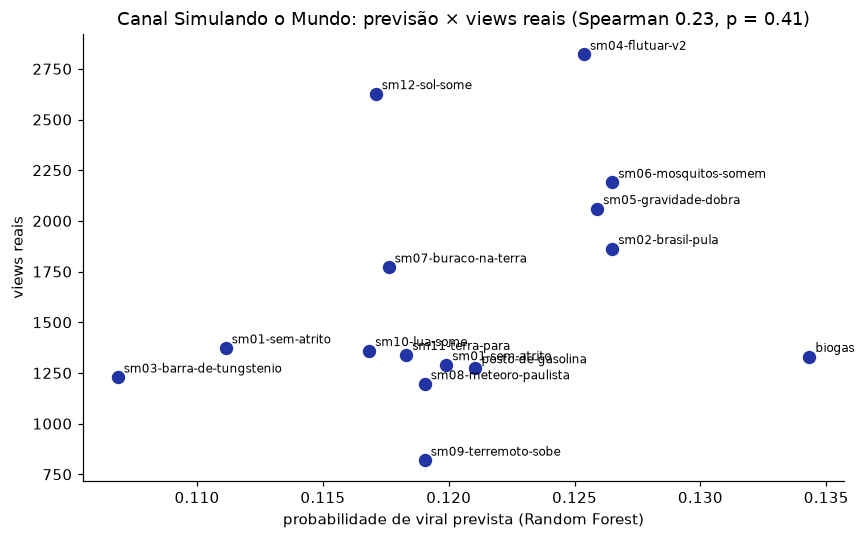

In [15]:
fig, eixo = plt.subplots(figsize=(8, 5))
eixo.scatter(canal[MELHOR], canal["views"], color="#2234A4", s=60)
for _, linha in canal.iterrows():
    eixo.annotate(linha["producao"], (linha[MELHOR], linha["views"]), fontsize=8, xytext=(4, 3), textcoords="offset points")
r = spearman(canal[MELHOR], canal["views"])
eixo.set(title=f"Canal Simulando o Mundo: previsão × views reais (Spearman {r['rho']:.2f}, p = {r['p-valor']:.2f})",
         xlabel=f"probabilidade de viral prevista ({MELHOR})", ylabel="views reais")
plt.tight_layout(); plt.savefig(FIGURAS / "canal_previsao_vs_views.png", bbox_inches="tight"); plt.show()

## 8. Comparação entre os vídeos do canal

O que separa os vídeos que foram melhor dos que foram pior? Com 15 vídeos isto é descritivo, não conclusivo:
para n = 15, uma correlação de Spearman só é significativa (5%) acima de cerca de 0,52 em módulo.

> As saídas das células com dados do YouTube Analytics (retenção, tempo visto, views até o 2º dia) não vão para o repositório público. Rode `python -m src.canal` e execute o notebook para vê-las.

In [ ]:
comparacao = canal[["producao", "publicado_em", "duracao_s", "views", "views_ate_dia2", "retencao_media_pct",
                    "tempo_medio_visto_s", "likes", "inscritos_ganhos"]].copy()
comparacao["publicado_em"] = pd.to_datetime(comparacao["publicado_em"]).dt.tz_convert("America/Sao_Paulo").dt.strftime("%d/%m %Hh")
comparacao.sort_values("views", ascending=False).reset_index(drop=True)

In [ ]:
relacoes = pd.DataFrame({
    variavel: spearman(canal[variavel], canal["views"])
    for variavel in ["duracao_s", "retencao_media_pct", "tempo_medio_visto_s"]
}).T
relacoes.index.name = "variável × views"
relacoes

## 9. Conclusões e análise crítica

*Números da execução de 12/11/2026. As views do canal mudam a cada nova exportação (`python -m src.canal`).*

**No dataset (10.780 Shorts depois da limpeza)**

- Os quatro modelos superam a base em ROC AUC (0,77 a 0,79 no teste). O **Random Forest**, escolhido pela validação
  cruzada (AUC 0,772), também teve o melhor resultado no teste: AUC 0,791 e F1 0,507. A **Regressão Logística** fica
  perto (AUC 0,779) e é bem mais fácil de explicar.
- **Acurácia engana aqui.** O KNN tem a maior acurácia (0,806) porque quase nunca responde “viral” (Recall 0,07): ele
  não tem `class_weight` e, com 20% de positivos, a maioria dos 51 vizinhos é quase sempre “não viral”. A base que
  nunca diz “viral” já chega a 0,800.
- **O que pesa:** a duração (na logística, Shorts mais longos têm mais chance: coeficiente +0,69) e o idioma declarado
  (português puxa para baixo, −1,93; inglês e outros puxam para cima). A descrição quase não muda nada.
- **Limitações do dataset:** as views são de um único dia de coleta e não há data de publicação, então vídeos antigos
  levam vantagem e o modelo não sabe a idade de cada um. Também não há tamanho do canal, que no estudo de Ling et al.
  foi o fator mais forte.

**No canal Simulando o Mundo (15 Shorts)**

- **O modelo acerta o nível.** Todos os 15 vídeos recebem probabilidade de 0,11 a 0,13 (a mediana no teste é 0,38), e
  de fato nenhum chegou perto do limiar de 13,9 milhões de views.
- **Mas não consegue ordenar os vídeos.** As probabilidades quase não variam porque, para o modelo, os 15 vídeos são
  quase iguais: mesma categoria, mesmo idioma, descrições parecidas e durações entre 51 e 75 s. Com as views totais,
  o Spearman vai de −0,20 a 0,23, sem nenhum resultado significativo. O único p < 0,05 (Random Forest × views até o 2º
  dia, ρ = 0,68, n = 11) aparece em 1 de 8 testes e não se repete nos outros modelos. Se os testes fossem
  independentes, a chance de ao menos um dar p < 0,05 por acaso seria de cerca de um terço, então não dá para tratar
  isso como acerto.
- **O que separa os vídeos do canal está no que o modelo não vê:** o tema, o gancho e quanto as pessoas assistem.
  Dentro do canal, a retenção média é a variável mais ligada às views (ρ = 0,38, ainda não significativa com 15 vídeos).
  A retenção só existe depois da publicação, então não serve para prever antes; mas é exatamente o que a pipeline já
  mede e usa para ajustar os próximos roteiros.
- **Dados do canal ainda incompletos:** o Analytics tem cerca de 2 dias de atraso. Os 4 vídeos mais novos ainda não
  têm a janela de 2 dias, e a retenção de 28% do `sm12-sol-some` é parcial.

**Para que serve, na prática:** um modelo de metadados funciona como filtro grosso (formato, idioma, duração), não
para escolher entre roteiros parecidos de um mesmo canal. Para isso é preciso dado do próprio canal (o ciclo de
aprendizados da pipeline) e mais vídeos.